# 01 - EDA and preprocessing

This notebook looks at the competition data (VisDrone2019-VID, 8 classes) before we train anything. Every section ends with a short note on what it means for later choices, and the last section lists the observations in one place.

The data folder should contain `train/`, `val/`, `test/` and `test_images.csv` exactly as downloaded from Kaggle. Locally it sits in the repo root, on Kaggle change `DATA` to the competition input folder. The figures are saved to `images/` so the report can use them.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

DATA = Path("..")          # folder with train/, val/, test/ and test_images.csv
FIGS = Path("../images")   # figures used in the report
FIGS.mkdir(exist_ok=True)

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 2)

## Loading the annotations

We read the COCO file of each split because it has everything in one place: boxes, ignore regions, track ids and the frame number. Ignore regions are stored once per class (8 copies of each), so we keep only the copy with `category_id == 1`. Boxes are `[x, y, w, h]` in pixels.

In [2]:
def load_split(split):
    coco = json.load(open(DATA / split / "annotations_coco.json"))
    images = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    anns = pd.DataFrame(coco["annotations"])
    anns = anns.merge(images[["image_id", "video", "frame_id", "width", "height"]], on="image_id")
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns = anns.drop(columns="bbox")

    boxes = anns[anns["iscrowd"] == 0].copy()
    boxes["cls"] = boxes["category_id"] - 1
    ignore = anns[(anns["iscrowd"] == 1) & (anns["category_id"] == 1)].copy()
    return images, boxes, ignore


train_img, train_box, train_ign = load_split("train")
val_img, val_box, val_ign = load_split("val")
test_img = pd.read_csv(DATA / "test_images.csv")

In [3]:
summary = pd.DataFrame({
    "clips": [train_img["video"].nunique(), val_img["video"].nunique(), test_img["clip"].nunique()],
    "frames": [len(train_img), len(val_img), len(test_img)],
    "boxes": [len(train_box), len(val_box), None],
    "ignore regions": [len(train_ign), len(val_ign), None],
}, index=["train", "val", "test"])
summary["frames per clip"] = summary["frames"] / summary["clips"]
summary["boxes per frame"] = summary["boxes"] / summary["frames"]
summary

,clips,frames,boxes,ignore regions,frames per clip,boxes per frame
train,56,24201,1.11e+06,63843.0,432.16,45.68
val,7,2846,1.14e+05,3995.0,406.57,40.10
test,48,3811,NaN,NaN,79.40,NaN


## Image resolutions

Resolution is fixed inside a clip but changes between clips, so we count clips, not frames.

In [4]:
def res_table(df, clip_col):
    res = df.groupby(clip_col)[["width", "height"]].first()
    return (res["width"].astype(str) + "x" + res["height"].astype(str)).value_counts()

pd.DataFrame({
    "train": res_table(train_img, "video"),
    "val": res_table(val_img, "video"),
    "test": res_table(test_img, "clip"),
}).fillna(0).astype(int)

,train,val,test
1344x756,11,2,7
1360x764,0,0,18
1360x765,1,0,0
1904x1071,30,2,0
1904x1072,0,0,4
1920x1080,1,0,11
2688x1512,11,1,0
2720x1530,2,1,0
3840x2160,0,1,0
680x382,0,0,3


## Class distribution

,train,val,train %,val %
person,328701,50312,29.7,44.1
bicycle,40255,6022,3.6,5.3
car,505301,31821,45.7,27.9
van,46940,6842,4.2,6.0
truck,30498,1359,2.8,1.2
tricycle,41349,5487,3.7,4.8
bus,9653,264,0.9,0.2
motor,102819,12025,9.3,10.5


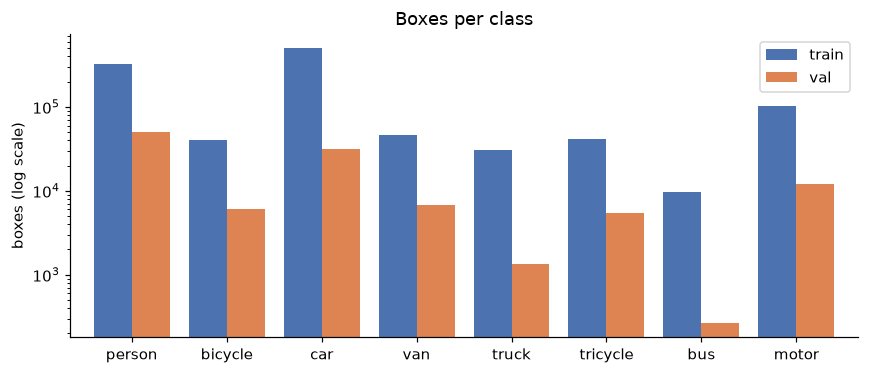

In [5]:
counts = pd.DataFrame({
    "train": train_box["cls"].value_counts().sort_index(),
    "val": val_box["cls"].value_counts().sort_index(),
})
counts.index = CLASSES
shares = (counts / counts.sum() * 100).round(1).add_suffix(" %")
display(pd.concat([counts, shares], axis=1))

ax = counts.plot.bar(figsize=(8, 3.5), color=["#4C72B0", "#DD8452"], width=0.8)
ax.set_yscale("log")
ax.set_ylabel("boxes (log scale)")
ax.set_title("Boxes per class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGS / "eda_classes.png")
plt.show()

Per clip the picture is very different. Each row below is one training clip (grouped by fold), and the colour is the share of each class in that clip.

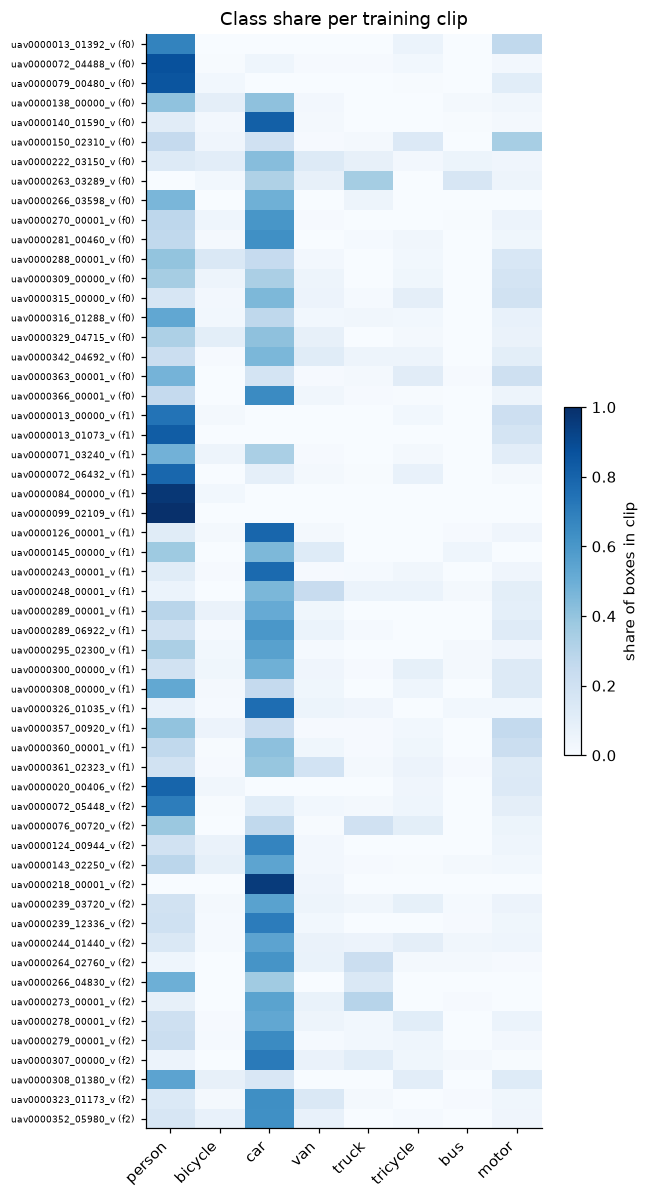

clips where the class appears at all:
person      55
bicycle     41
car         49
van         46
truck       39
tricycle    39
bus         24
motor       50


In [6]:
folds = pd.read_csv("../folds.csv")
per_clip = pd.crosstab(train_box["video"], train_box["cls"], normalize="index")
per_clip.columns = CLASSES
order = folds.sort_values(["fold", "clip"])["clip"]
per_clip = per_clip.reindex(order)

fig, ax = plt.subplots(figsize=(6, 11))
im = ax.imshow(per_clip.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=45, ha="right")
labels = [f"{c} (f{f})" for c, f in zip(order, folds.set_index("clip").loc[order, "fold"])]
ax.set_yticks(range(len(labels)), labels, fontsize=6)
fig.colorbar(im, ax=ax, fraction=0.04, label="share of boxes in clip")
ax.set_title("Class share per training clip")
plt.tight_layout()
plt.savefig(FIGS / "eda_classes_per_clip.png")
plt.show()

print("clips where the class appears at all:")
print((per_clip > 0).sum().to_string())

## Box sizes

COCO calls a box small if its area is below 32², medium up to 96², and large above that. We use $\sqrt{w \cdot h}$ so the thresholds become 32 and 96 pixels. The last columns show the same split after resizing each frame so its long side is 1280, which is the input size we plan to train at.

In [7]:
def size_groups(side):
    return pd.cut(side, [0, 32, 96, np.inf], labels=["small", "medium", "large"])

for df in (train_box, val_box):
    df["side"] = np.sqrt(df["w"] * df["h"])
    df["side_1280"] = df["side"] * 1280 / df[["width", "height"]].max(axis=1)

rows = []
for name, df in [("train", train_box), ("val", val_box)]:
    native = size_groups(df["side"]).value_counts(normalize=True) * 100
    resized = size_groups(df["side_1280"]).value_counts(normalize=True) * 100
    rows.append({"split": name, "median side px": df["side"].median(),
                 **{f"{k} %": native[k] for k in native.index},
                 **{f"{k} % @1280": resized[k] for k in resized.index}})
pd.DataFrame(rows).set_index("split").round(1)

,median side px,medium %,small %,large %,small % @1280,medium % @1280,large % @1280
split,,,,,,,
train,45.8,63.5,24.9,11.6,54.2,42.8,3.0
val,52.4,69.5,19.2,11.3,48.4,49.7,2.0


In [8]:
by_class = train_box.groupby("cls")["side"].describe(percentiles=[0.1, 0.5, 0.9])[["10%", "50%", "90%"]]
by_class["small %"] = train_box.groupby("cls")["side"].apply(lambda s: (s < 32).mean() * 100)
by_class.index = CLASSES
by_class.round(1)

,10%,50%,90%,small %
person,19.8,35.8,60.0,39.5
bicycle,24.9,41.4,71.5,24.4
car,28.3,57.0,120.9,16.3
van,28.1,49.8,124.1,21.4
truck,32.7,73.5,181.0,9.4
tricycle,24.2,54.9,103.9,21.0
bus,41.8,113.4,264.7,4.1
motor,20.2,40.2,67.8,30.4


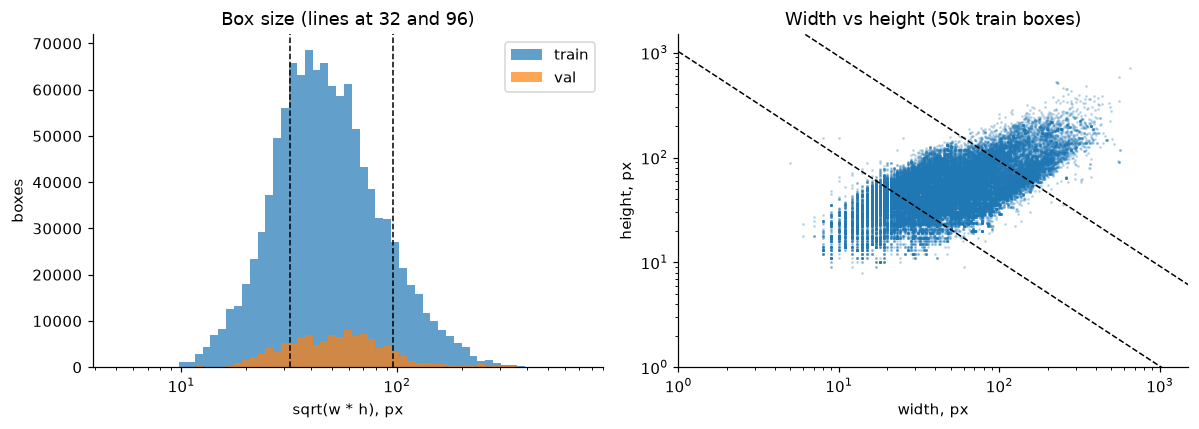

In [9]:
sample = train_box.sample(50_000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bins = np.logspace(np.log10(5), np.log10(train_box["side"].max()), 60)
axes[0].hist(train_box["side"], bins=bins, alpha=0.7, label="train")
axes[0].hist(val_box["side"], bins=bins, alpha=0.7, label="val")
for t in (32, 96):
    axes[0].axvline(t, color="k", ls="--", lw=1)
axes[0].set_xscale("log")
axes[0].set_xlabel("sqrt(w * h), px")
axes[0].set_ylabel("boxes")
axes[0].set_title("Box size (lines at 32 and 96)")
axes[0].legend()

axes[1].scatter(sample["w"], sample["h"], s=1, alpha=0.2)
w = np.logspace(0, 3.2, 100)
for t in (32, 96):
    axes[1].plot(w, t**2 / w, "k--", lw=1)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(1, 1500)
axes[1].set_ylim(1, 1500)
axes[1].set_xlabel("width, px")
axes[1].set_ylabel("height, px")
axes[1].set_title("Width vs height (50k train boxes)")

plt.tight_layout()
plt.savefig(FIGS / "eda_box_sizes.png")
plt.show()

## Objects per frame

Frames without any box count as zero, so we start from the image table and not from the boxes.

In [10]:
def per_frame(images, boxes):
    n = boxes.groupby("image_id").size()
    return images.set_index("image_id")["video"].to_frame().assign(n=n).fillna({"n": 0})

train_pf = per_frame(train_img, train_box)
val_pf = per_frame(val_img, val_box)

pd.DataFrame({
    name: {"mean": df["n"].mean(), "median": df["n"].median(),
           "p99": df["n"].quantile(0.99), "max": df["n"].max(),
           "empty frames": (df["n"] == 0).sum()}
    for name, df in [("train", train_pf), ("val", val_pf)]
}).round(1)

,train,val
mean,45.7,40.1
median,43.0,37.0
p99,142.0,112.6
max,180.0,116.0
empty frames,3.0,0.0


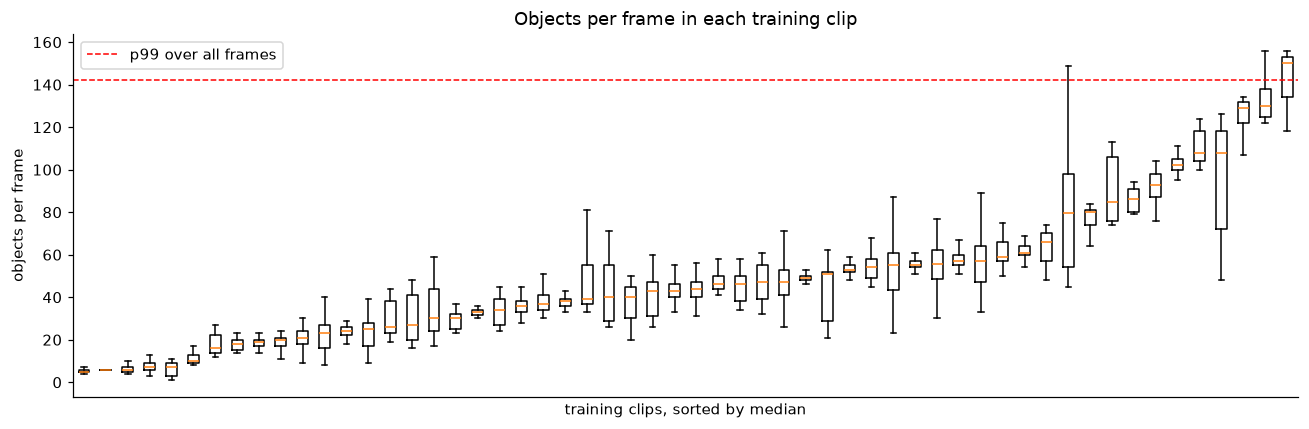

In [11]:
clip_order = train_pf.groupby("video")["n"].median().sort_values().index
data = [train_pf.loc[train_pf["video"] == c, "n"] for c in clip_order]

fig, ax = plt.subplots(figsize=(12, 4))
ax.boxplot(data, showfliers=False)
ax.set_xticks([])
ax.set_xlabel("training clips, sorted by median")
ax.set_ylabel("objects per frame")
ax.axhline(train_pf["n"].quantile(0.99), color="r", ls="--", lw=1, label="p99 over all frames")
ax.legend()
ax.set_title("Objects per frame in each training clip")
plt.tight_layout()
plt.savefig(FIGS / "eda_objects_per_frame.png")
plt.show()

## Ignore regions

Ignore regions cover crowds and areas that were too dense to label. Detections inside them are not counted in scoring. Here we check how many frames have them, how much of the frame they cover (the union, so overlapping regions are not counted twice), and how many labelled boxes overlap them. The last number matters for masking: if we paint a region grey, we must not paint over a labelled object.

In [12]:
def ignored_fraction(ign, images, cell=8):
    # union of regions on a coarse grid (one cell = 8x8 px), per frame
    frac = pd.Series(0.0, index=images["image_id"])
    for image_id, g in ign.groupby("image_id"):
        W, H = g["width"].iloc[0], g["height"].iloc[0]
        mask = np.zeros((H // cell + 1, W // cell + 1), bool)
        for x, y, w, h in g[["x", "y", "w", "h"]].values:
            mask[int(y // cell):int(np.ceil((y + h) / cell)), int(x // cell):int(np.ceil((x + w) / cell))] = True
        frac[image_id] = mask.mean()
    return frac


def box_cover(boxes, ign):
    # for every box: the largest share of its area inside a single ignore region
    m = boxes[["id", "image_id", "x", "y", "w", "h"]].merge(
        ign[["image_id", "x", "y", "w", "h"]], on="image_id", suffixes=("", "_i"))
    iw = (np.minimum(m["x"] + m["w"], m["x_i"] + m["w_i"]) - np.maximum(m["x"], m["x_i"])).clip(lower=0)
    ih = (np.minimum(m["y"] + m["h"], m["y_i"] + m["h_i"]) - np.maximum(m["y"], m["y_i"])).clip(lower=0)
    m["cover"] = iw * ih / (m["w"] * m["h"])
    return m.groupby("id")["cover"].max().reindex(boxes["id"], fill_value=0)


rows = {}
for name, img, box, ign in [("train", train_img, train_box, train_ign), ("val", val_img, val_box, val_ign)]:
    frac = ignored_fraction(ign, img)
    cover = box_cover(box, ign)
    rows[name] = {
        "frames with regions %": (frac > 0).mean() * 100,
        "regions per such frame": len(ign) / (frac > 0).sum(),
        "mean ignored area %": frac.mean() * 100,
        "p90 ignored area %": frac.quantile(0.9) * 100,
        "boxes touching a region": (cover > 0).sum(),
        "boxes >= 50% covered": (cover >= 0.5).sum(),
    }
pd.DataFrame(rows).round(1)

,train,val
frames with regions %,74.7,50.4
regions per such frame,3.5,2.8
mean ignored area %,2.6,1.7
p90 ignored area %,6.3,6.8
boxes touching a region,38801.0,3730.0
boxes >= 50% covered,11883.0,1208.0


## How much do boxes move between frames

Every box has a `track_id`, so we can find the same object `k` frames later and compare the two boxes. If the IoU between them is still high after 5 frames, then neighbouring frames are almost copies of each other and training on all of them mostly repeats the same examples.

In [13]:
cols = ["video", "track_id", "frame_id", "x", "y", "w", "h", "side"]
tracks = train_box[cols].drop_duplicates(["video", "track_id", "frame_id"])

rows = []
for k in [1, 2, 5, 10, 20]:
    later = tracks.copy()
    later["frame_id"] -= k
    m = tracks.merge(later, on=["video", "track_id", "frame_id"], suffixes=("", "_k"))
    iw = (np.minimum(m["x"] + m["w"], m["x_k"] + m["w_k"]) - np.maximum(m["x"], m["x_k"])).clip(lower=0)
    ih = (np.minimum(m["y"] + m["h"], m["y_k"] + m["h_k"]) - np.maximum(m["y"], m["y_k"])).clip(lower=0)
    inter = iw * ih
    iou = inter / (m["w"] * m["h"] + m["w_k"] * m["h_k"] - inter)
    shift = np.hypot(m["x"] + m["w"] / 2 - m["x_k"] - m["w_k"] / 2, m["y"] + m["h"] / 2 - m["y_k"] - m["h_k"] / 2)
    rows.append({"k": k, "pairs": len(m), "median IoU": iou.median(), "share IoU > 0.5": (iou > 0.5).mean(),
                 "median shift px": shift.median(), "median shift / box side": (shift / m["side"]).median()})

shift_table = pd.DataFrame(rows).set_index("k")
shift_table.round(2)

,pairs,median IoU,share IoU > 0.5,median shift px,median shift / box side
k,,,,,
1,1097628,0.90,0.96,2.00,0.04
2,1090077,0.81,0.86,3.91,0.08
5,1067598,0.60,0.59,9.43,0.21
10,1031089,0.36,0.39,18.79,0.42
20,961789,0.10,0.26,36.24,0.81


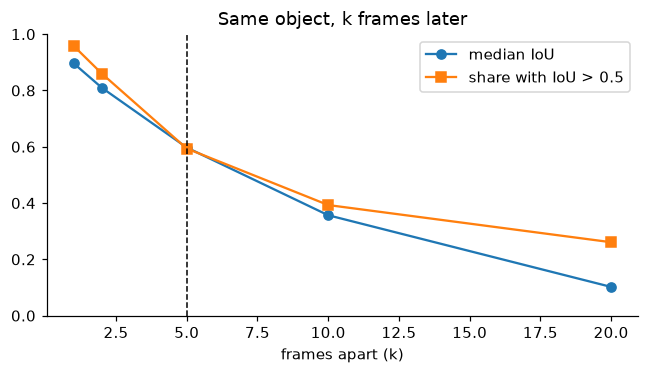

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(shift_table.index, shift_table["median IoU"], "o-", label="median IoU")
ax.plot(shift_table.index, shift_table["share IoU > 0.5"], "s-", label="share with IoU > 0.5")
ax.axvline(5, color="k", ls="--", lw=1)
ax.set_xlabel("frames apart (k)")
ax.set_ylim(0, 1)
ax.set_title("Same object, k frames later")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "eda_frame_shift.png")
plt.show()

## Folds

`src/folds.py` splits the 56 training clips into 3 folds with `GroupKFold`, using the clip as the group, so all frames of a clip stay in one fold. It balances the number of frames per fold, not the classes. Fold 0 is the split we tune on.

In [15]:
fold_stats = folds.groupby("fold").agg(clips=("clip", "size"), frames=("n_frames", "sum"), boxes=("n_boxes", "sum"))
class_share = folds.groupby("fold")[CLASSES].sum()
class_share = (class_share.div(class_share.sum(axis=1), axis=0) * 100).round(1)
pd.concat([fold_stats, class_share], axis=1)

,clips,frames,boxes,person,bicycle,car,van,truck,tricycle,bus,motor
fold,,,,,,,,,,,
0,19,8080,370434,33.5,5.8,38.3,3.3,1.7,4.1,0.8,12.4
1,19,8082,384593,33.2,2.5,43.8,4.9,1.3,2.5,0.9,10.9
2,18,8039,350489,22.0,2.6,55.6,4.6,5.5,4.7,0.9,4.3


## Ground truth on sample frames

A quick visual check that the labels line up with the objects. One frame from each of 6 clips, spread over the folds. Ignore regions are the light grey rectangles. Made with `python src/viz_gt.py --split-dir train --folds folds.csv --out images/gt_samples.jpg`.

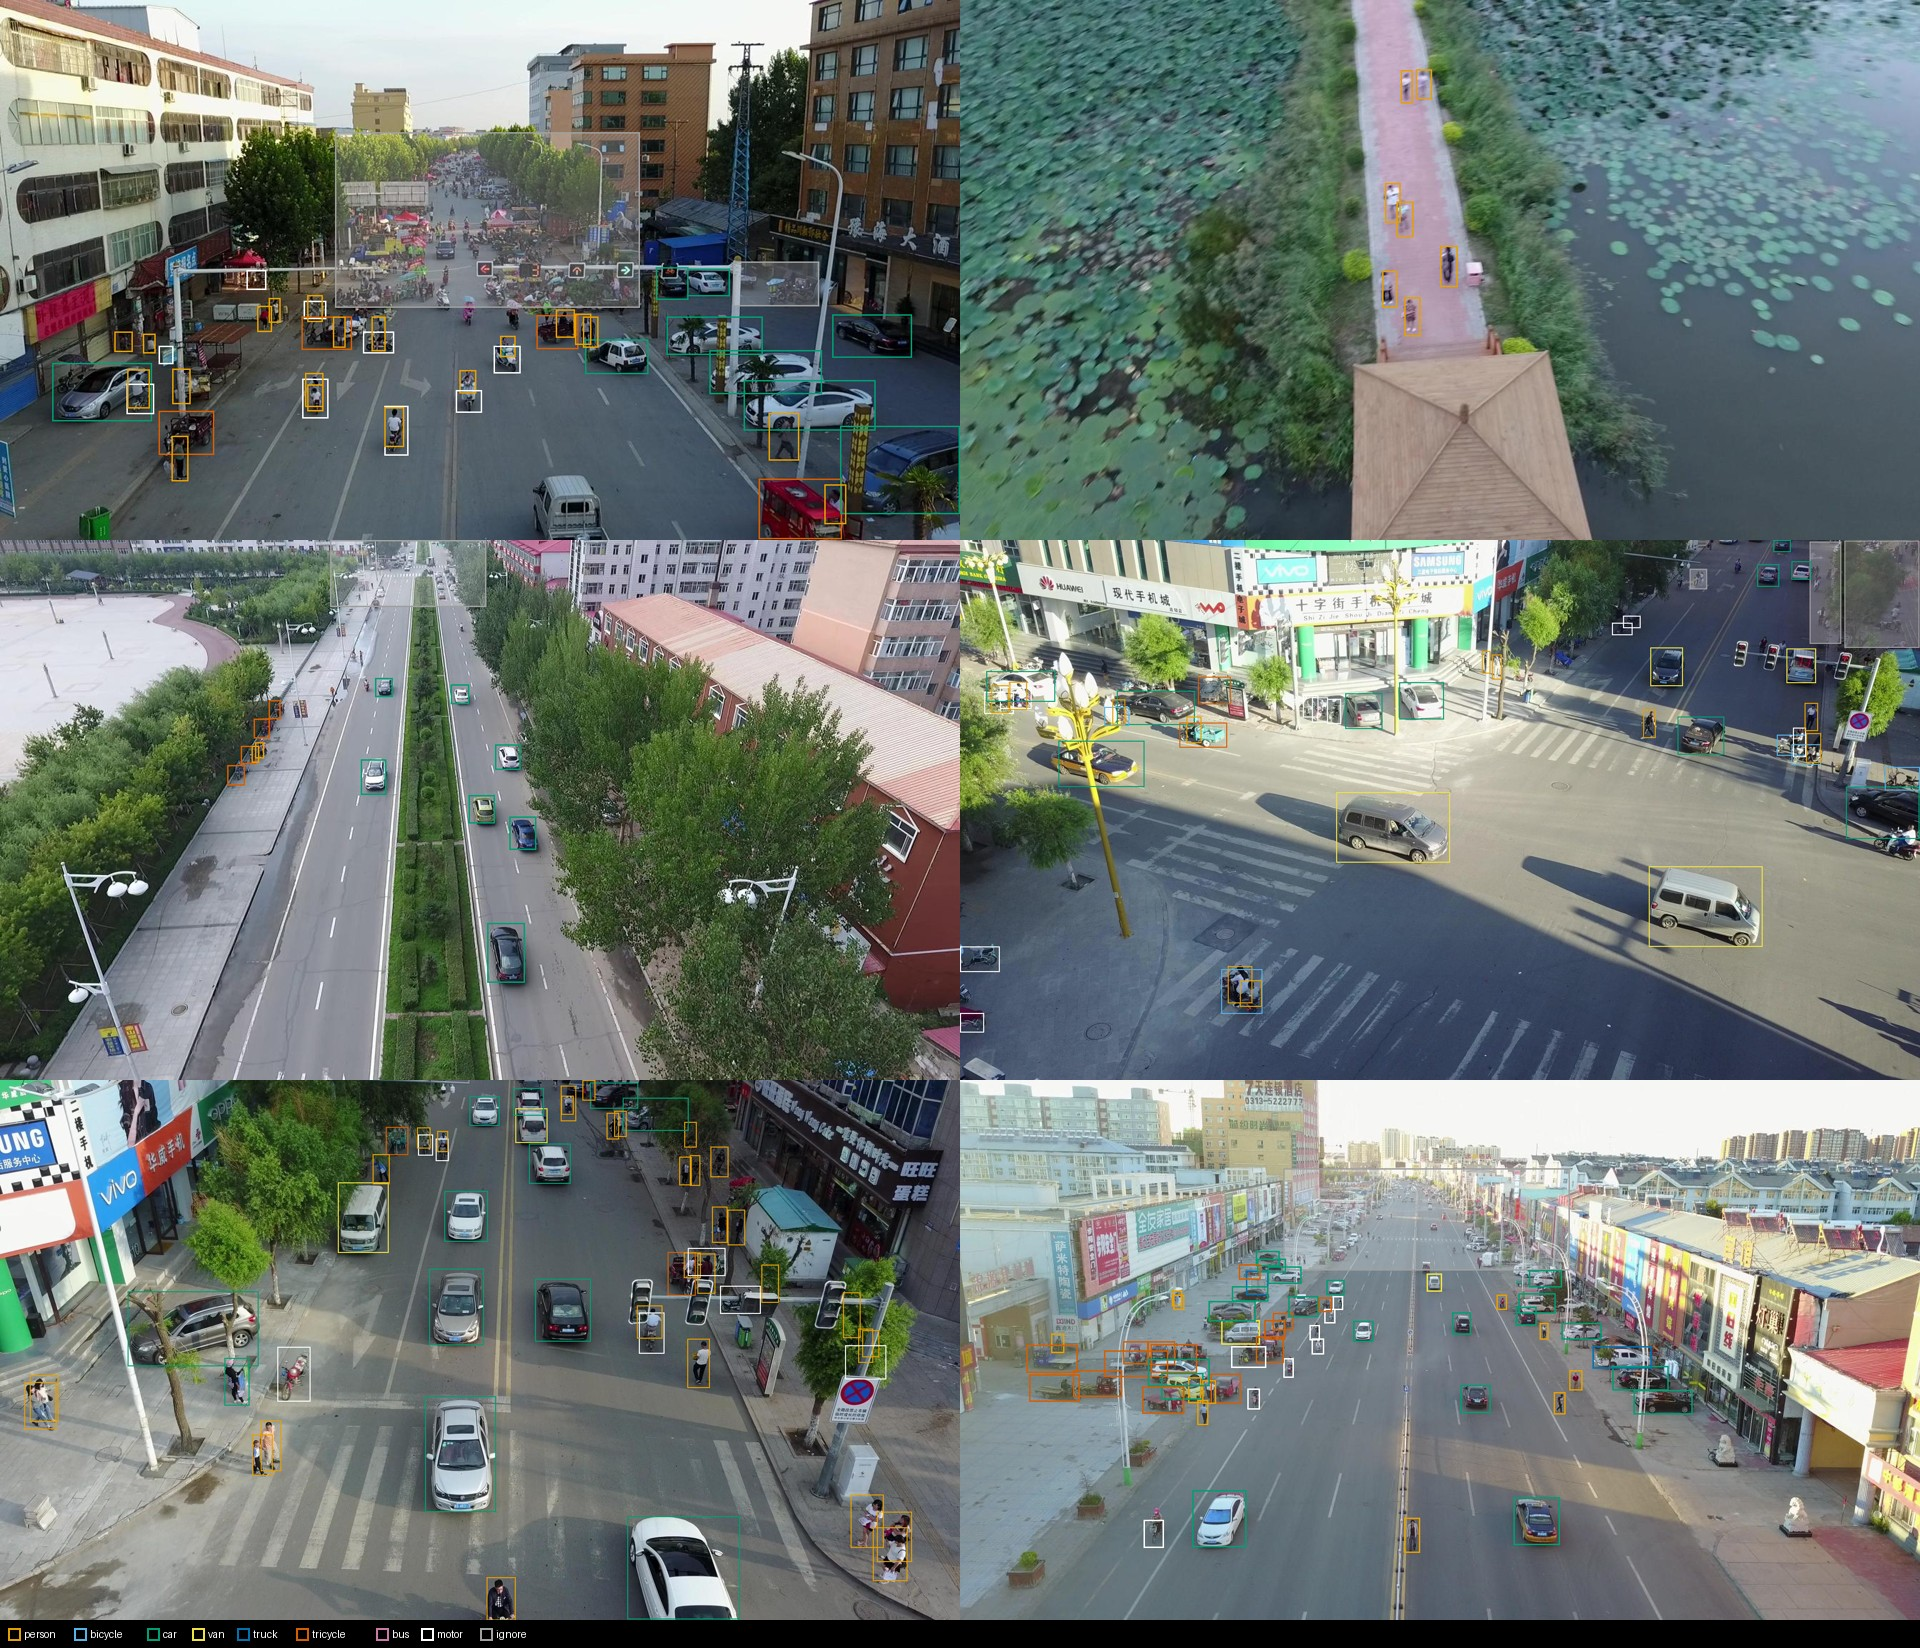

In [16]:
display(Image(filename=str(FIGS / "gt_samples.jpg"), width=900))

## Data preparation

The competition already gives YOLO labels, ignore regions and a COCO file, so there is not much to convert. What we add on top is in `src/convert.py`:

- Evaluation ground truth. COCO evaluation matches crowd regions per class, so a region must exist once for every class to ignore detections of any class inside it. The supplied COCO file already has this (8 copies of every region in both splits), so the script only cuts it into per-fold and every-5th-frame subsets.
- Masked training images. For YOLO training we paint ignore regions with the mean colour of the image, so the model is not punished for "finding" unlabelled objects there. Pixels inside labelled boxes are kept, because many boxes overlap the regions (see the table above). Frames without regions are just symlinked. `--no-mask` gives the same lists without masking, for the on/off experiment.
- Frame step. We train on every 5th frame of each clip, based on the IoU table above.

```bash
python src/folds.py   --split-dir train --out folds.csv
python src/convert.py coco --split-dir train --out prep/coco/train_step5.json --frame-step 5 --folds folds.csv
python src/convert.py coco --split-dir val   --out prep/coco/val.json
python src/convert.py yolo --split-dir train --out prep/yolo --frame-step 5 --folds folds.csv
```

Below, the original frame (left) next to the masked one (right). The labelled people inside the region on the pavilion keep their pixels. Made with `python src/viz_gt.py --split-dir train --compare-dir prep/yolo/masked/images/train --folds folds.csv --n 2 --out images/mask_check.jpg`.

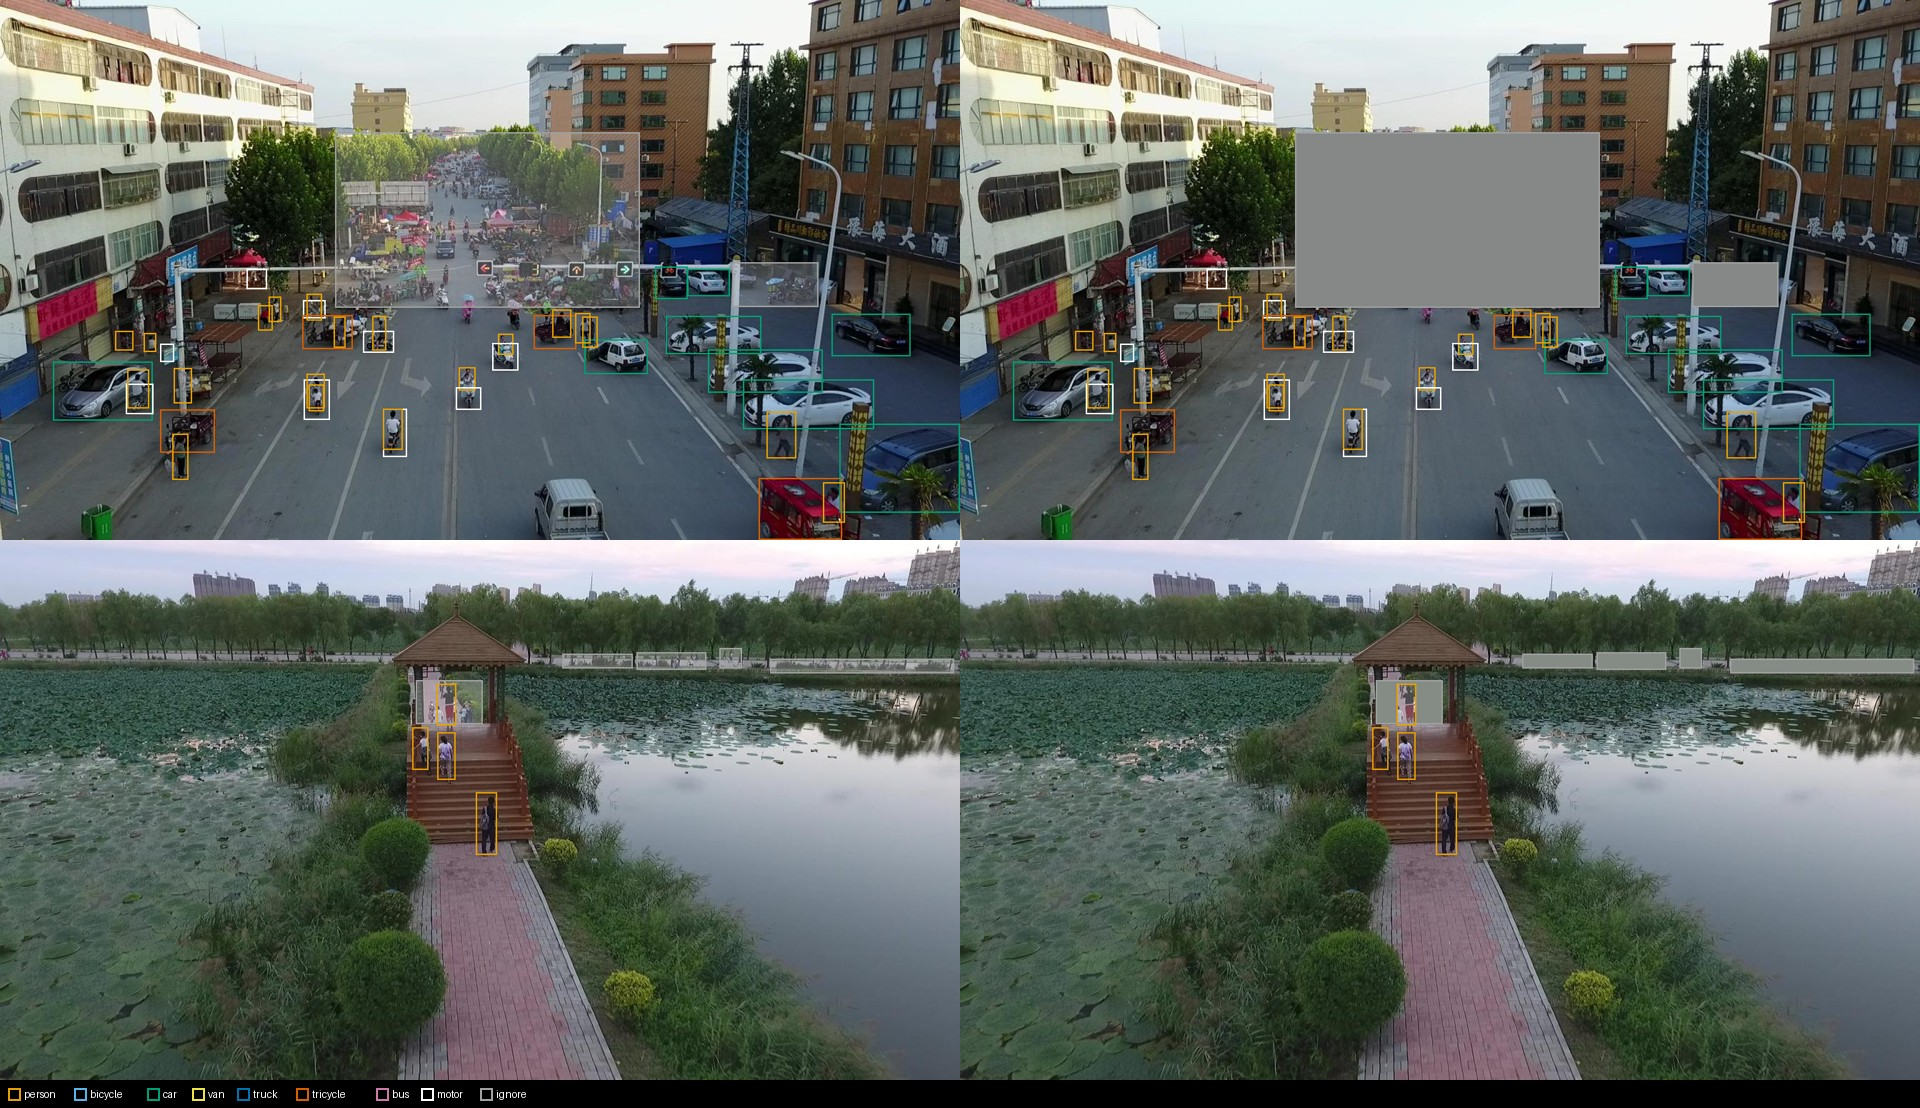

In [17]:
display(Image(filename=str(FIGS / "mask_check.jpg"), width=900))

## Observations

Each line is something we saw above and what we do about it.

1. Most objects are small. At native resolution a quarter of the boxes are below 32 px, and after resizing to 1280 more than half are (54% in train). Person and motor are the smallest classes, with a median side of 36 and 40 px. So we train at 1280 instead of 640 and test a P2 head and SAHI slicing later.
2. Frames are crowded but not extreme. The median is 43 objects per frame, p99 is 142 and the maximum is 180 in train (116 in val). 300 RT-DETR queries are enough, and `max_det=500` never cuts the ground truth.
3. The classes are very unbalanced. Car and person make up 75% of the train boxes, truck is 2.8% and bus only 0.9%, and bus appears in just 24 of 56 clips. Copy-paste for bus and truck is worth a try, and bus AP on val (264 boxes) will be noisy.
4. The official val set does not look like train: 44% person against 30%, 28% car against 46%, and only 7 clips. We tune on fold 0 of train and use val only for the final check.
5. Test resolutions differ from train. 33 of 48 test clips are 1360 px wide or less (some only 680x382), while 44 of 56 train clips are 1904 px wide or more. Resizing every frame to the same long side keeps object sizes closer between train and test. Random crops at native resolution would show objects about twice as big as in test, so that Day 4 run needs care.
6. Neighbouring frames are almost copies. One frame later the same object has a median IoU of 0.90 with itself and moved 2 px. Five frames later the IoU is 0.60 and it moved about a fifth of its size. Training on every 5th frame keeps most of the variety for a fifth of the cost. Step 2 is a later experiment.
7. Ignore regions are everywhere but small: they are in 75% of train frames but cover only 2.6% of the frame on average. 11,883 train boxes are at least half inside a region, so masking has to keep the pixels of labelled boxes.
8. The folds are balanced by frames but not by classes (fold 2 has 56% cars, folds 0 and 1 have 38% and 44%). Scores from different folds are not directly comparable, so we only compare runs on the same fold.